# Online Retail Data Analysis and Customer Behavior Insights

This notebook analyzes the genuine UCI Online Retail workbook. It separates raw data from the cleaned sales view, documents exclusions, and computes all findings from the source at runtime. Run from the repository root.

## 1. Setup and source data

The helper downloads and extracts the UCI workbook when it is not already in `dataset/`. If the download is unavailable, follow the manual instructions in the repository README.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_cleaning import locate_workbook, load_raw_data, clean_data, build_rfm, cancellation_summary, run_analysis, product_summary, cohort_retention
sns.set_theme(style='whitegrid', context='notebook')
print('Project root:', ROOT)

Project root: C:\Users\Ashwin\Desktop\data analytics\Python-EDA-Project


In [2]:
workbook = locate_workbook(ROOT / 'dataset')
raw = load_raw_data(workbook)
print(f'Source workbook: {workbook.name} | rows: {len(raw):,} | columns: {raw.shape[1]}')
display(raw.head())

Source workbook: Online Retail.xlsx | rows: 541,909 | columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Raw data inspection and quality

Inspect schema, types, missingness, and exact duplicate count before cleaning. The raw DataFrame is retained unchanged.

In [3]:
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_pct': (raw.isna().mean()*100).round(2)}))
print('Exact duplicate rows:', f'{raw.duplicated().sum():,}')
display(raw.describe(include='all').T)

,dtype,missing,missing_pct
InvoiceNo,object,0,0.00
StockCode,object,0,0.00
Description,object,1454,0.27
Quantity,int64,0,0.00
InvoiceDate,datetime64[us],0,0.00
UnitPrice,float64,0,0.00
CustomerID,float64,135080,24.93
Country,str,0,0.00


Exact duplicate rows: 5,268


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Cleaning and transaction audit

Cleaning runs on a copy. Anonymous transactions remain available for sales totals, while customer analyses use rows with an observed customer ID. Credit-note invoices and non-positive quantities or prices are excluded from the valid-sales view and summarized separately.

In [4]:
sales, audit = clean_data(raw)
display(pd.Series(audit, name='row_count'))
print('Cleaned shape:', sales.shape)
display(sales.head())

source_rows                                             541909
duplicate_rows                                            5268
missing_customer_rows                                   135080
cancellation_rows                                         9288
nonpositive_quantity_rows                                10624
nonpositive_price_rows                                    2517
deduplicated_rows                                       536641
missing_dates_after_parse                                    0
valid_sales_rows                                        524878
missing_customer_rows_removed_from_customer_analysis    132186
invalid_or_cancelled_rows_excluded                       11763
Name: row_count, dtype: int64

Cleaned shape: (524878, 15)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,Year,Month,YearMonth,Day,Weekday,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,2010-12,1,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,1,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,2010-12,1,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,1,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,2010-12,1,Wednesday,8


In [5]:
display(cancellation_summary(raw))
display(sales[['Quantity','UnitPrice','TotalPrice','Year','Month','Day','Weekday','Hour']].describe().T)

,deduplicated_source_rows,cancellation_or_negative_rows,cancellation_invoice_rows,negative_quantity_rows,cancellation_invoice_value_abs,negative_quantity_value_abs
0,536641,10587,9251,10587,893979.73,893979.73


,count,mean,std,min,25%,50%,75%,max
Quantity,524878.0,10.616600,156.280031,1.000,1.00,4.00,11.00,80995.00
UnitPrice,524878.0,3.922573,36.093028,0.001,1.25,2.08,4.13,13541.33
TotalPrice,524878.0,20.275399,271.693566,0.001,3.90,9.92,17.70,168469.60
Year,524878.0,2010.921904,0.268323,2010.000,2011.00,2011.00,2011.00,2011.00
Month,524878.0,7.552237,3.508164,1.000,5.00,8.00,11.00,12.00
Day,524878.0,15.022472,8.660738,1.000,7.00,15.00,22.00,31.00
Hour,524878.0,13.073991,2.442994,6.000,11.00,13.00,15.00,20.00


## 4. Sales performance

Revenue is the sum of valid positive line values. An invoice is counted once as an order. These figures cover the dataset's historical observation period.

In [6]:
orders = sales.groupby('InvoiceNo').TotalPrice.sum()
monthly = sales.groupby('YearMonth').TotalPrice.sum().sort_index()
daily = sales.set_index('InvoiceDate').TotalPrice.resample('D').sum()
print(f"Valid revenue: £{sales.TotalPrice.sum():,.2f}")
print(f"Valid sales lines: {len(sales):,} | unique invoices: {sales.InvoiceNo.nunique():,}")
print(f"Known customers: {sales.CustomerID.nunique():,} | average order value: £{orders.mean():,.2f}")
print(f"Peak revenue month: {monthly.idxmax()} (£{monthly.max():,.2f})")
display(monthly.rename('Revenue GBP').to_frame())
display(daily.rename('Daily revenue GBP').to_frame().head(15))
display(orders.describe().to_frame('Order value GBP'))

Valid revenue: £10,642,110.80
Valid sales lines: 524,878 | unique invoices: 19,960
Known customers: 4,338 | average order value: £533.17
Peak revenue month: 2011-11 (£1,503,866.78)


,Revenue GBP
YearMonth,
2010-12,821452.730
2011-01,689811.610
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,757841.380


,Daily revenue GBP
InvoiceDate,
2010-12-01,58776.79
2010-12-02,47629.42
2010-12-03,46898.63
2010-12-04,0.00
2010-12-05,31364.63
2010-12-06,54624.15
2010-12-07,99553.85
2010-12-08,45235.36
2010-12-09,53548.19


,Order value GBP
count,19960.000000
mean,533.171884
std,1780.412288
min,0.380000
25%,151.695000
50%,303.300000
75%,493.462500
max,168469.600000


## 5. Product and geography performance

Products are grouped by stock code with their most frequent description as a label. Country totals aggregate valid sales revenue. Stock codes can also represent service or adjustment items; inspect these before drawing merchandise recommendations.

In [7]:
products = product_summary(sales)
display(products.nlargest(10, 'Units'))
display(products.head(10))
country_revenue = sales.groupby('Country').TotalPrice.sum().sort_values(ascending=False)
display(country_revenue.head(15).rename('Revenue GBP').to_frame())


,Units,Revenue,Description
StockCode,,,
23843,80995,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
23166,78033,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
22197,56898,51334.47,POPCORN HOLDER
84077,54951,13814.01,WORLD WAR 2 GLIDERS ASSTD DESIGNS
85099B,48371,94159.81,JUMBO BAG RED RETROSPOT
85123A,37641,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
21212,36396,21246.45,PACK OF 72 RETROSPOT CAKE CASES
84879,36362,58927.62,ASSORTED COLOUR BIRD ORNAMENT
23084,30739,66870.03,RABBIT NIGHT LIGHT


,Units,Revenue,Description
StockCode,,,
DOT,706,206248.77,DOTCOM POSTAGE
22423,13851,174156.54,REGENCY CAKESTAND 3 TIER
23843,80995,168469.60,"PAPER CRAFT , LITTLE BIRDIE"
85123A,37641,104462.75,WHITE HANGING HEART T-LIGHT HOLDER
47566,18283,99445.23,PARTY BUNTING
85099B,48371,94159.81,JUMBO BAG RED RETROSPOT
23166,78033,81700.92,MEDIUM CERAMIC TOP STORAGE JAR
POST,3150,78101.88,POSTAGE
M,6984,77750.27,Manual


,Revenue GBP
Country,
United Kingdom,9001744.094
Netherlands,285446.340
EIRE,283140.520
Germany,228678.400
France,209625.370
Australia,138453.810
Spain,61558.560
Switzerland,57067.600
Belgium,41196.340


## 6. Customer behavior and time patterns

Customer spend and frequency are calculated for known IDs. Day-of-week and hour plots use invoice line revenue. The source records timestamps as supplied by the retailer.

In [8]:
customer = sales.dropna(subset=['CustomerID']).groupby('CustomerID').agg(
    Spend=('TotalPrice','sum'), Orders=('InvoiceNo','nunique'), Items=('Quantity','sum'))
display(customer.nlargest(10, 'Spend'))
display(customer.Orders.value_counts().sort_index().head(20).rename('Customer count').to_frame())
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
display(sales.groupby('Weekday').agg(Revenue=('TotalPrice','sum'), Lines=('InvoiceNo','size')).reindex(weekday_order))
display(sales.groupby('Hour').agg(Revenue=('TotalPrice','sum'), Lines=('InvoiceNo','size')).sort_index())

,Spend,Orders,Items
CustomerID,,,
14646.0,280206.02,73,196915
18102.0,259657.30,60,64124
17450.0,194390.79,46,69973
16446.0,168472.50,2,80997
14911.0,143711.17,201,80240
12415.0,124914.53,21,77374
14156.0,117210.08,55,57768
17511.0,91062.38,31,64549
16029.0,80850.84,63,40108


,Customer count
Orders,
1,1493
2,835
3,508
4,388
5,242
6,172
7,143
8,98
9,68


,Revenue,Lines
Weekday,,
Monday,1775782.071,92466
Tuesday,2175700.511,98726
Wednesday,1847074.380,91467
Thursday,2199292.570,100213
Friday,1837470.491,79667
Saturday,NaN,<NA>
Sunday,806790.781,62339


,Revenue,Lines
Hour,,
6,4.250,1
7,31059.210,379
8,283750.680,8797
9,990054.991,33684
10,1444814.771,47597
11,1236573.290,55420
12,1439324.660,75986
13,1261195.200,69993
14,1177907.521,65057


## 7. RFM segmentation

Recency uses the day after the latest valid purchase in the complete sales view. Frequency counts distinct invoices; Monetary sums positive sales. Average percentile ranks place tied values in the same score band. Scores need not produce equally sized groups. These exploratory segments are not a validated propensity model.

In [9]:
rfm = build_rfm(sales)
display(rfm.sort_values('Monetary', ascending=False).head(10))
display(rfm.groupby('Segment').agg(Customers=('Monetary','size'), MedianRecency=('Recency','median'), MedianOrders=('Frequency','median'), Revenue=('Monetary','sum')).sort_values('Revenue', ascending=False))

,Recency,Frequency,Monetary,R,F,M,Segment
CustomerID,,,,,,,
14646.0,2,73,280206.02,4,4,4,Champions
18102.0,1,60,259657.30,4,4,4,Champions
17450.0,9,46,194390.79,4,4,4,Champions
16446.0,1,2,168472.50,4,2,4,Loyal customers
14911.0,2,201,143711.17,4,4,4,Champions
12415.0,25,21,124914.53,3,4,4,Champions
14156.0,10,55,117210.08,4,4,4,Champions
17511.0,3,31,91062.38,4,4,4,Champions
16029.0,39,63,80850.84,3,4,4,Champions


,Customers,MedianRecency,MedianOrders,Revenue
Segment,,,,
Champions,1299,15.0,6.0,6467066.421
At risk,565,93.0,4.0,996737.721
Needs attention,1959,134.0,1.0,944328.502
Loyal customers,515,22.0,2.0,479076.250


## 8. Revenue concentration and cohort retention

Pareto ranks products by valid revenue. Cohorts group customers by first observed purchase month and show the share returning in later months. Cohort retention requires customer IDs and multiple observed months.

In [10]:
product_revenue = products.Revenue
product_share = product_revenue.cumsum() / product_revenue.sum()
products_for_80 = int((product_share < .8).sum() + 1)
print(f'{products_for_80:,} stock codes account for at least 80% of valid revenue, out of {len(products):,}.')
retention = cohort_retention(sales)
display(retention.style.format('{:.0%}', na_rep='Not observed'))


803 stock codes account for at least 80% of valid revenue, out of 3,922.


MonthsSinceFirstPurchase,0,1,2,3,4,5,6,7,8,9,10,11,12
Cohort,,,,,,,,,,,,,
2010-12,100%,37%,32%,38%,36%,40%,36%,35%,35%,40%,37%,50%,27%
2011-01,100%,22%,27%,23%,32%,29%,25%,24%,30%,33%,36%,12%,Not observed
2011-02,100%,19%,19%,28%,27%,25%,25%,28%,25%,31%,7%,Not observed,Not observed
2011-03,100%,15%,25%,20%,22%,17%,27%,23%,28%,9%,Not observed,Not observed,Not observed
2011-04,100%,21%,20%,21%,20%,23%,22%,26%,7%,Not observed,Not observed,Not observed,Not observed
2011-05,100%,19%,17%,17%,21%,23%,26%,10%,Not observed,Not observed,Not observed,Not observed,Not observed
2011-06,100%,17%,16%,26%,23%,33%,10%,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed
2011-07,100%,18%,21%,22%,27%,11%,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed
2011-08,100%,21%,25%,24%,12%,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed,Not observed


## 9. Visualizations

The pipeline saves all figures under `visualizations/`. Monthly revenue and customer/product/country views are generated from the same valid-sales DataFrame analyzed above.

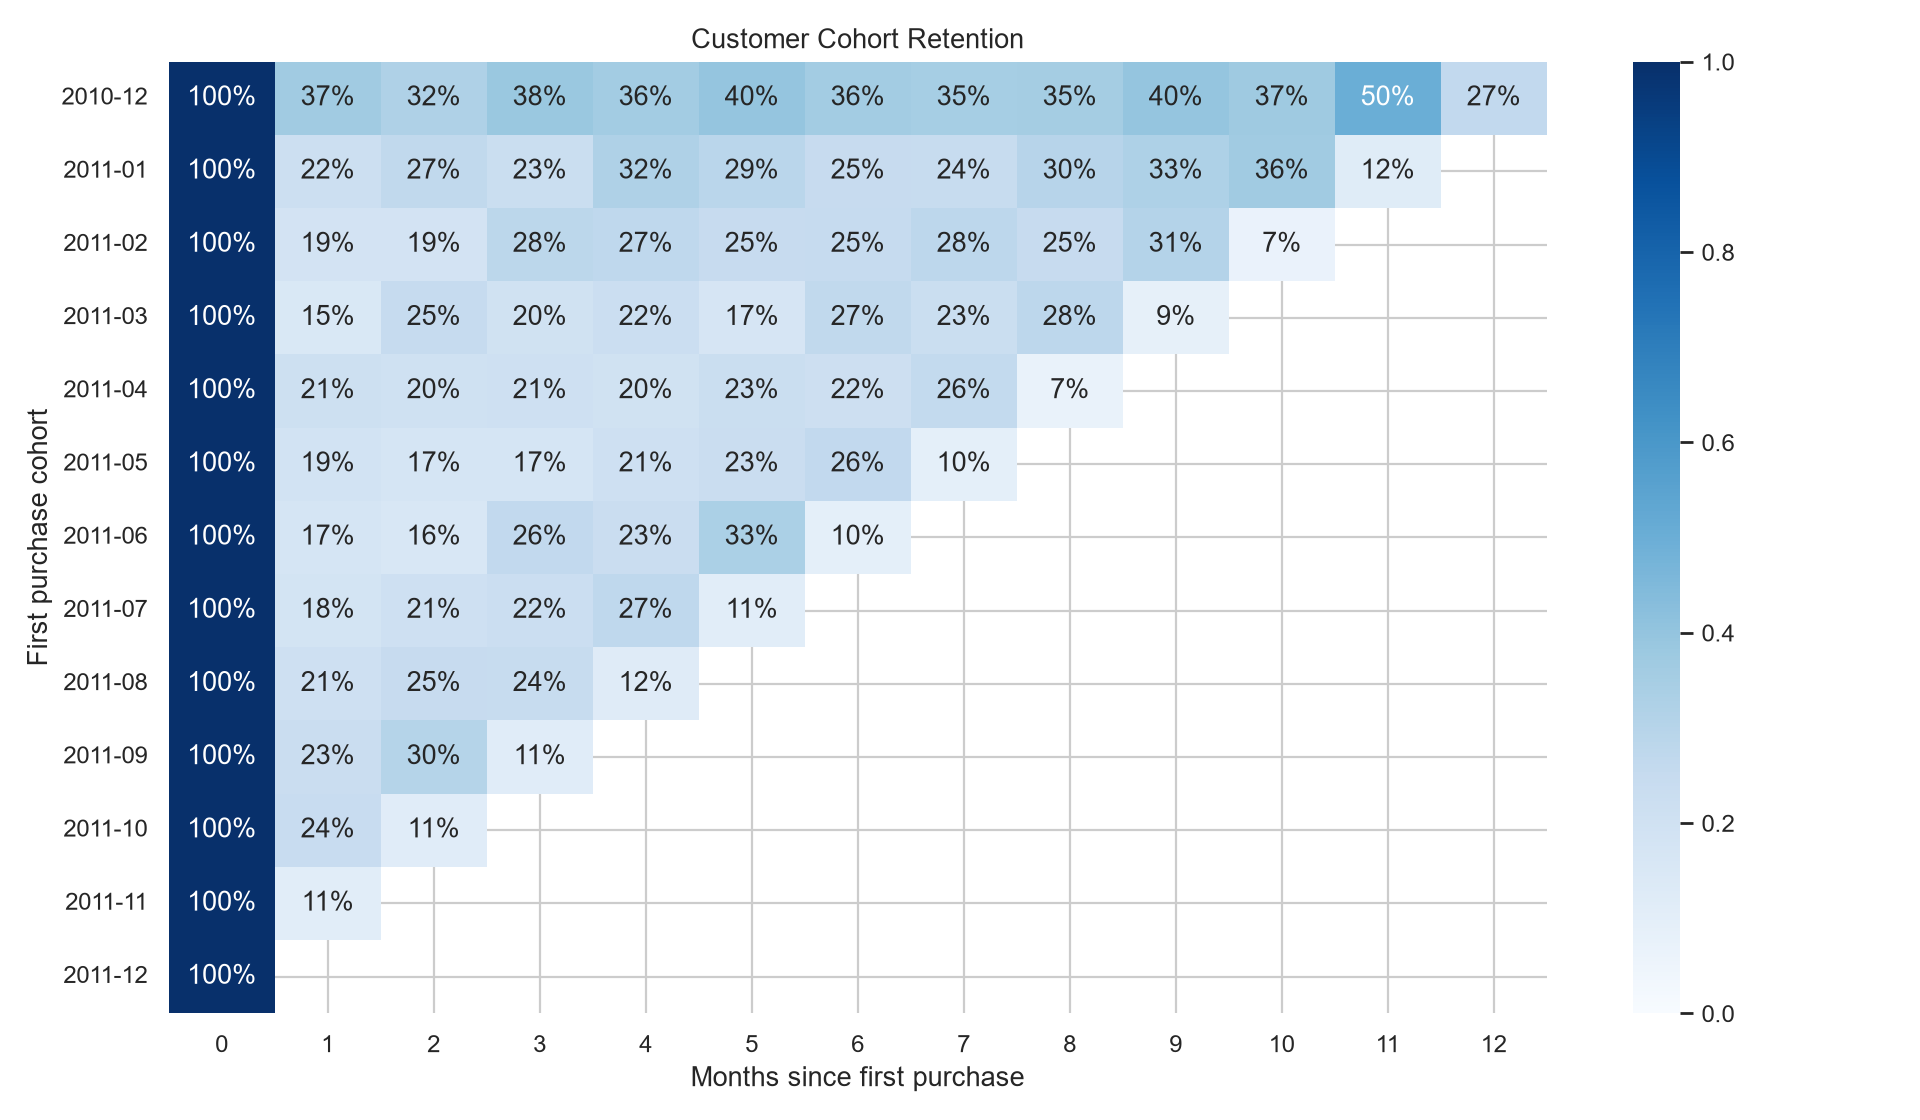

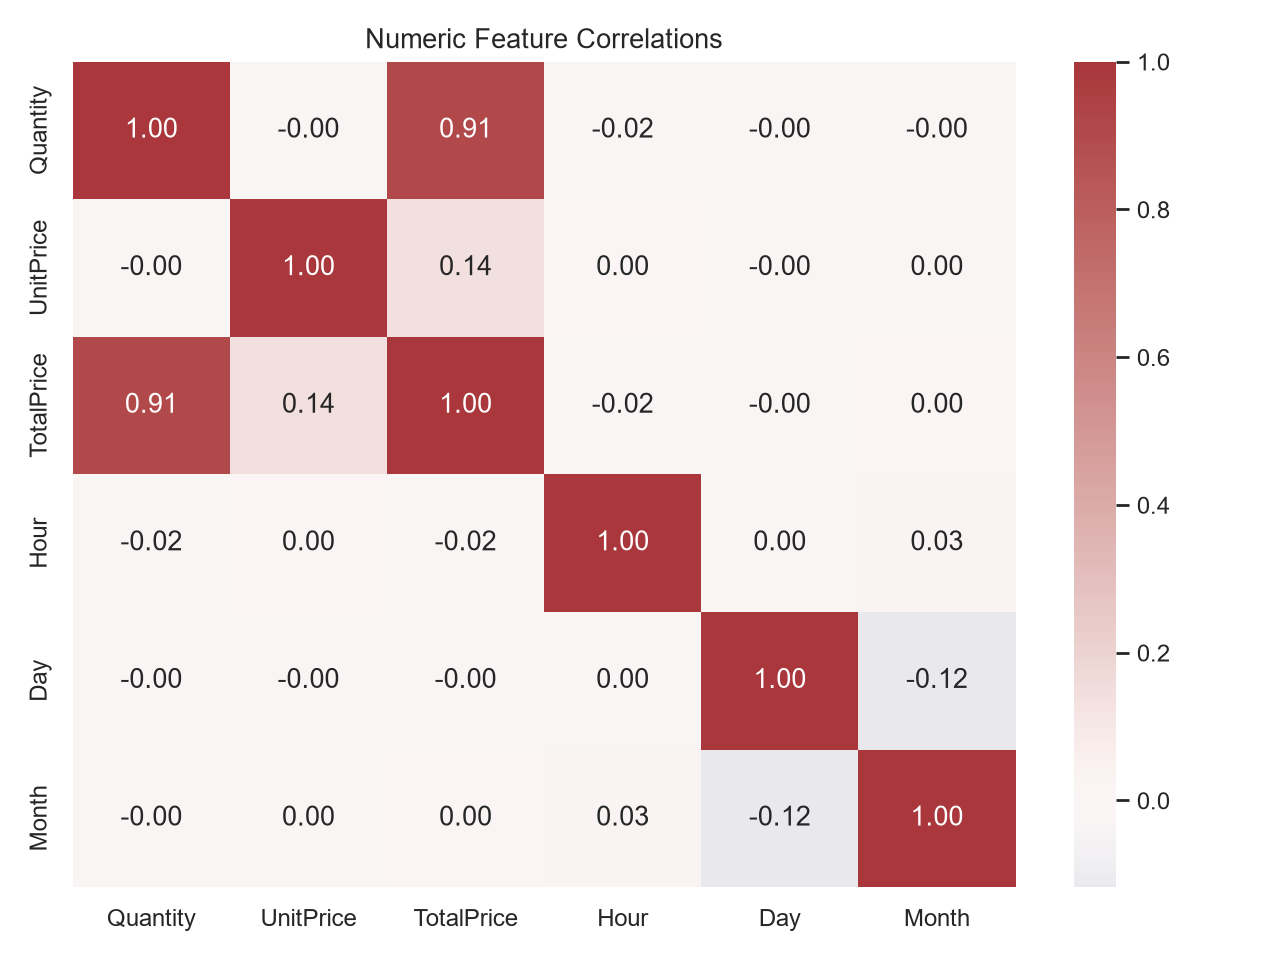

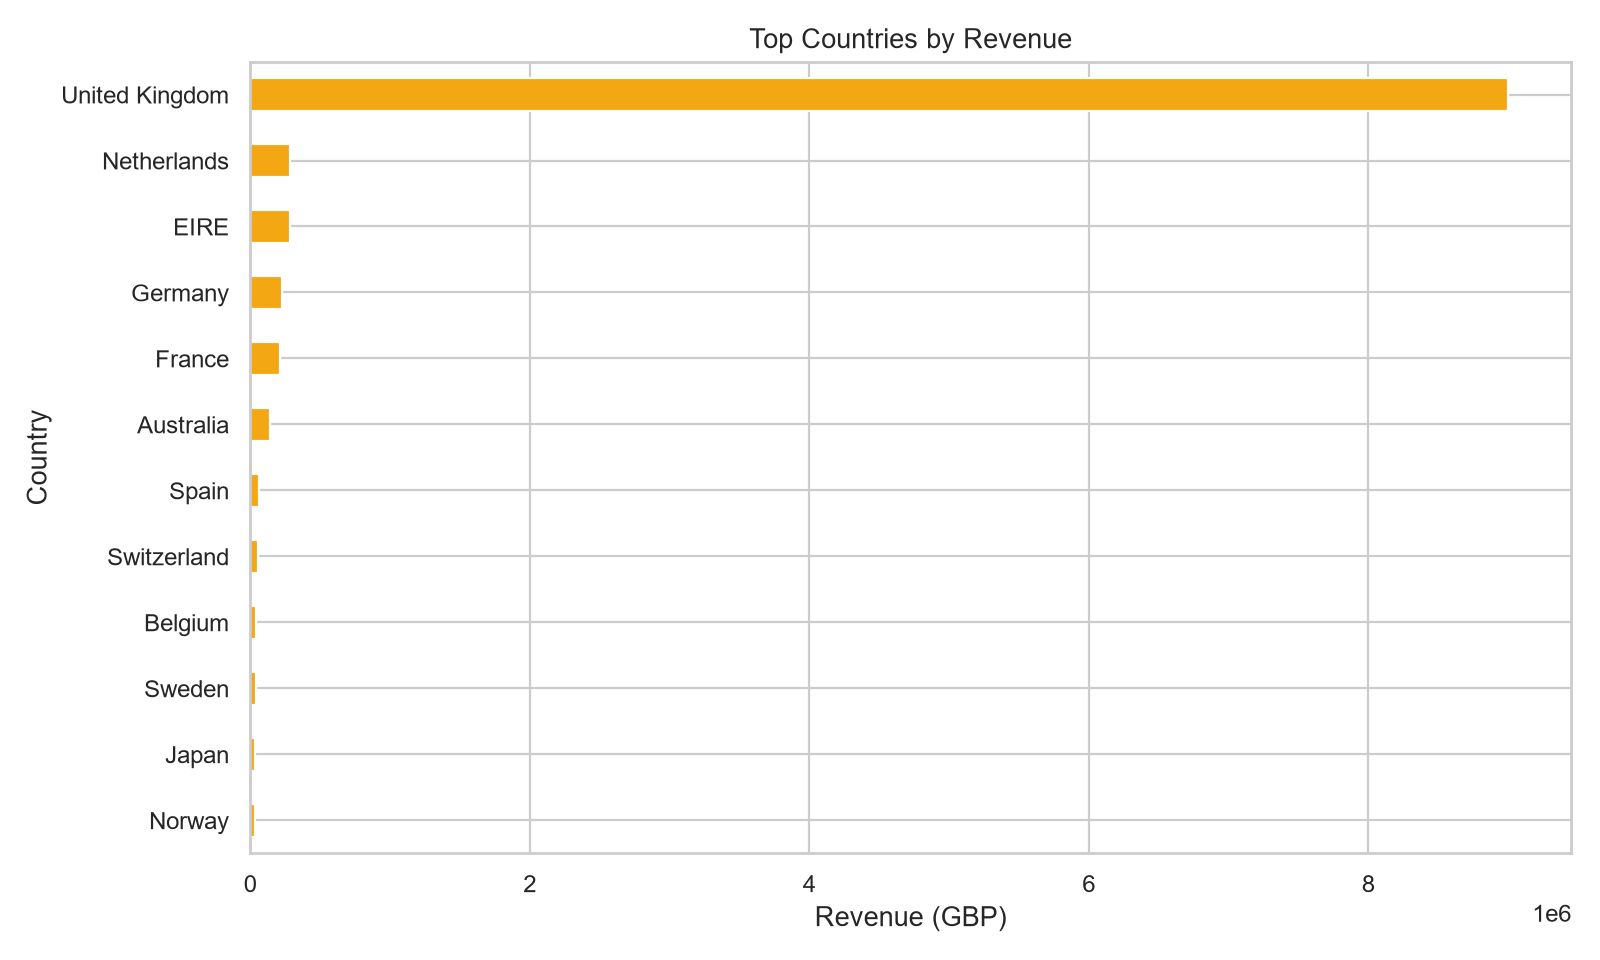

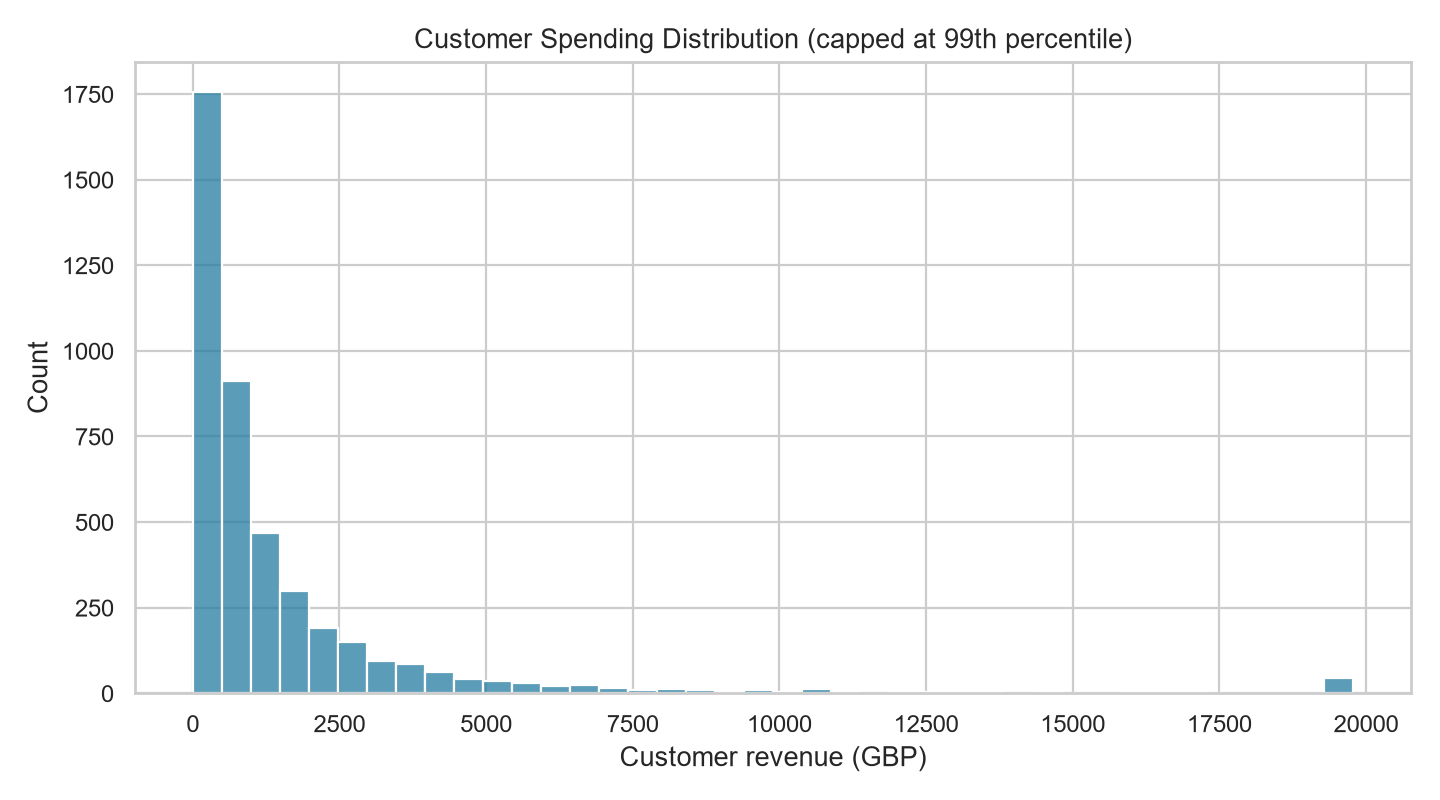

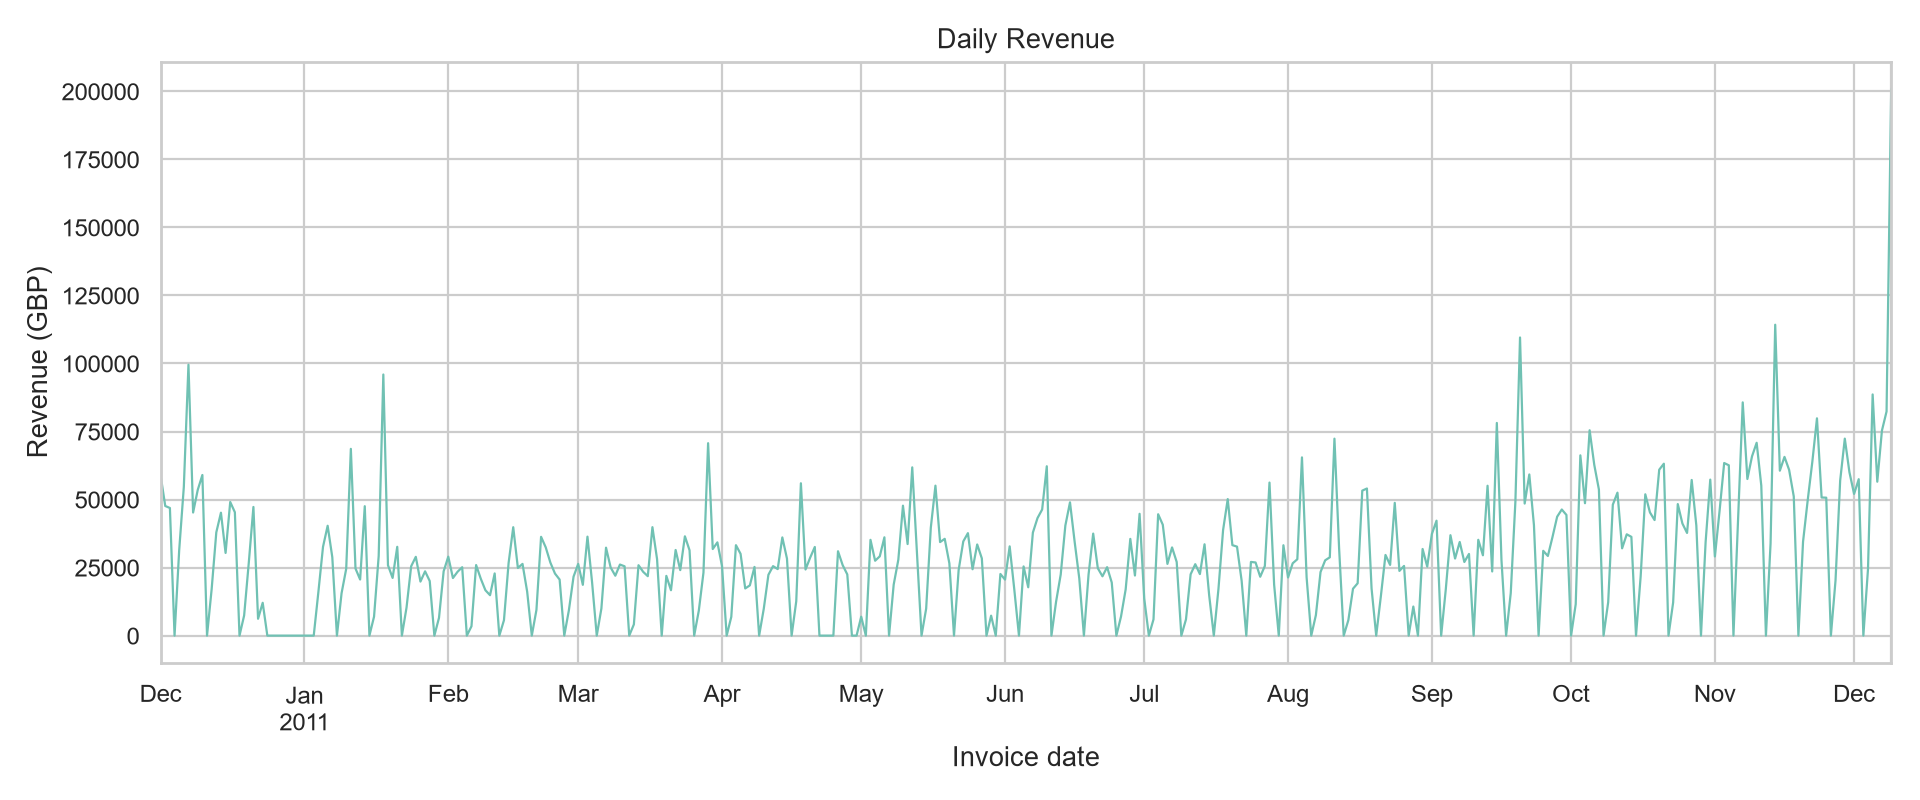

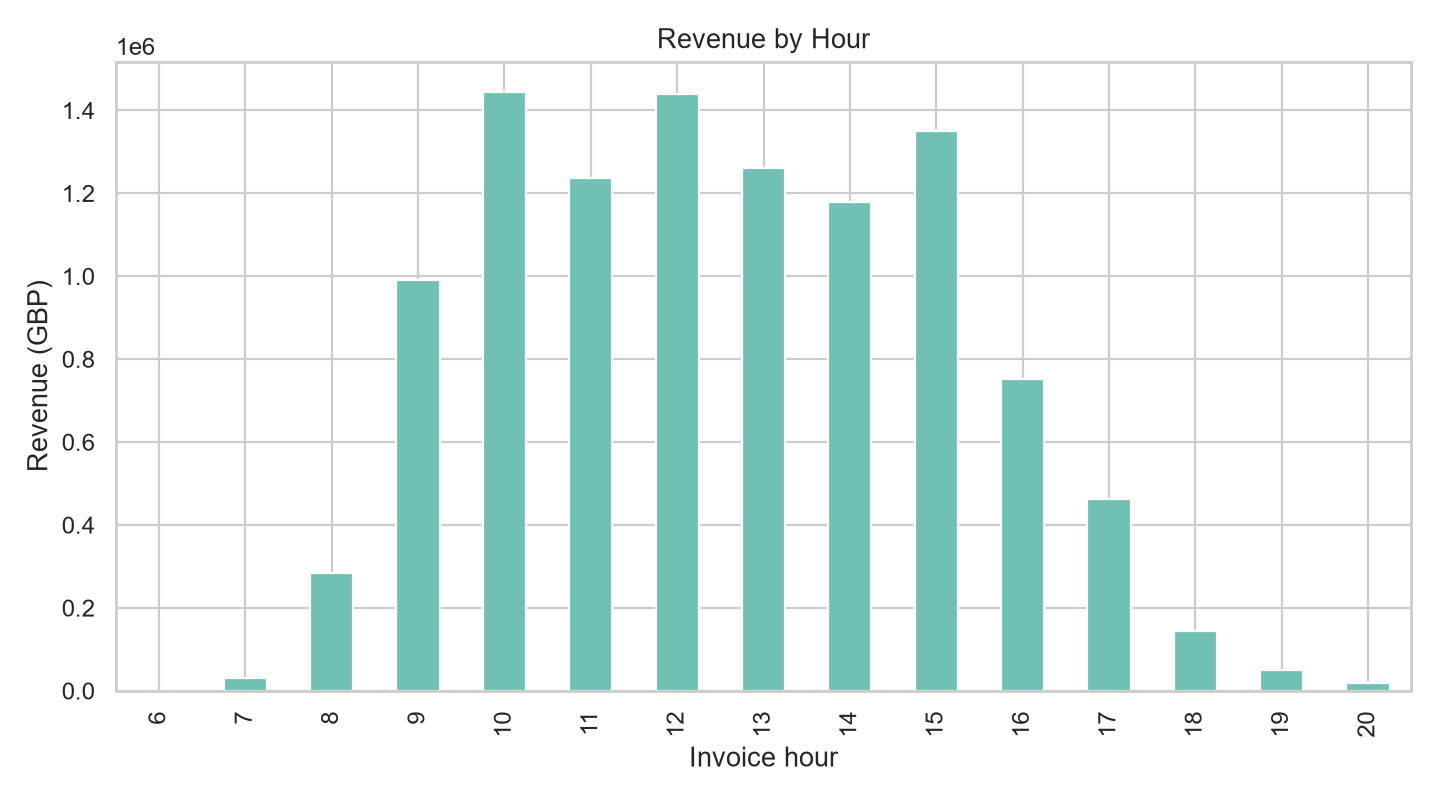

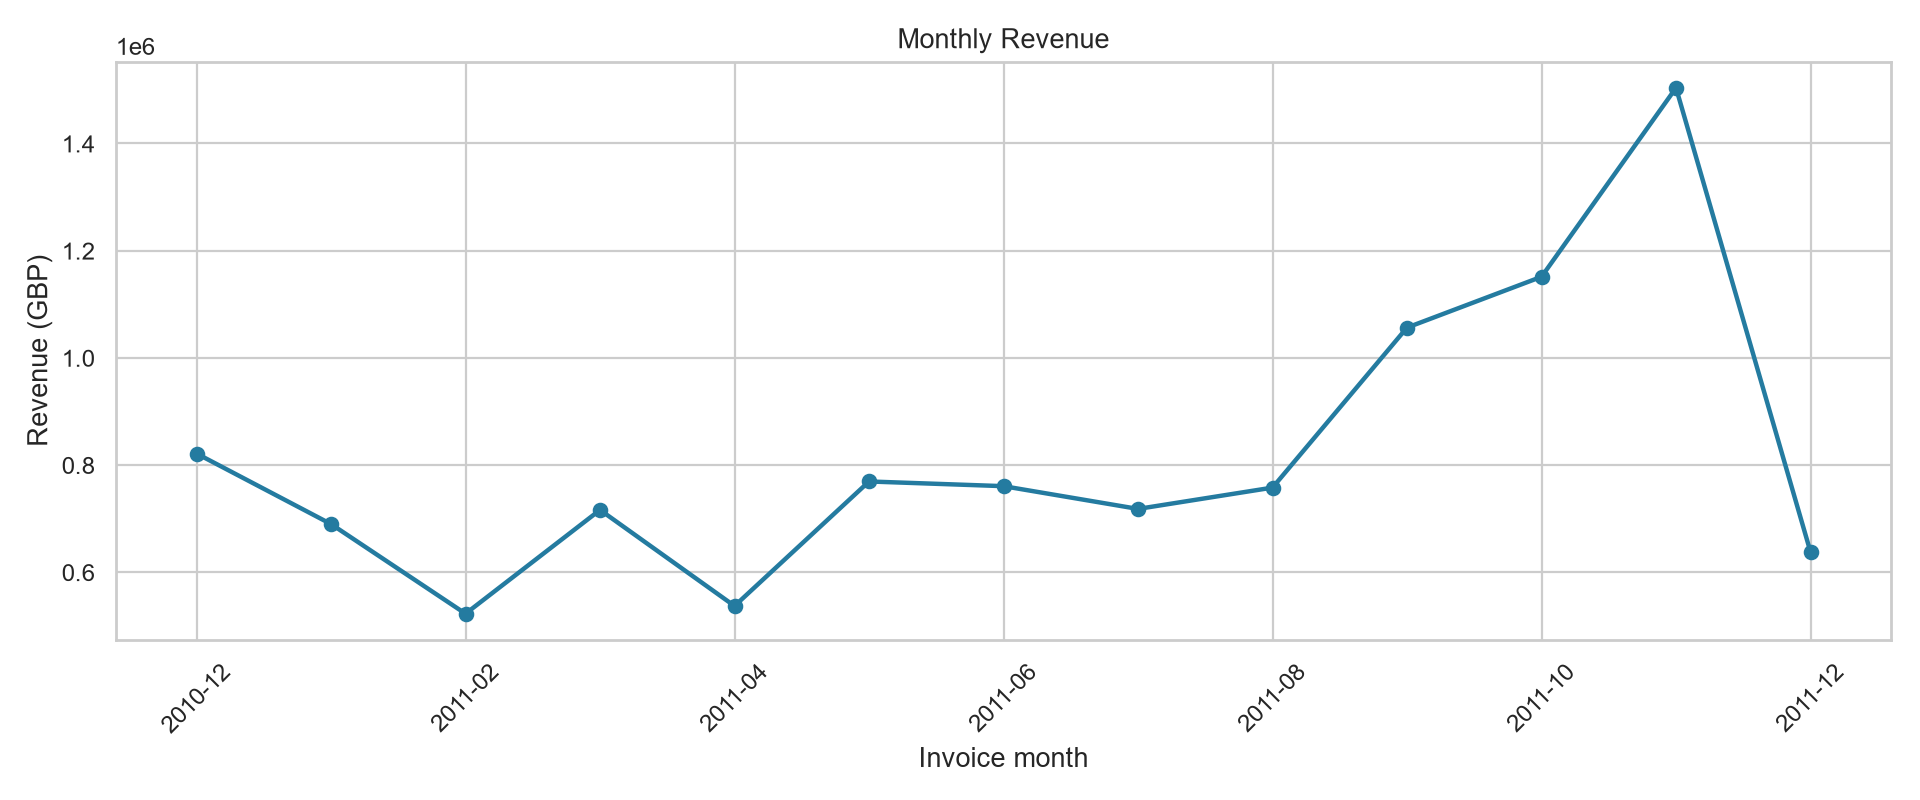

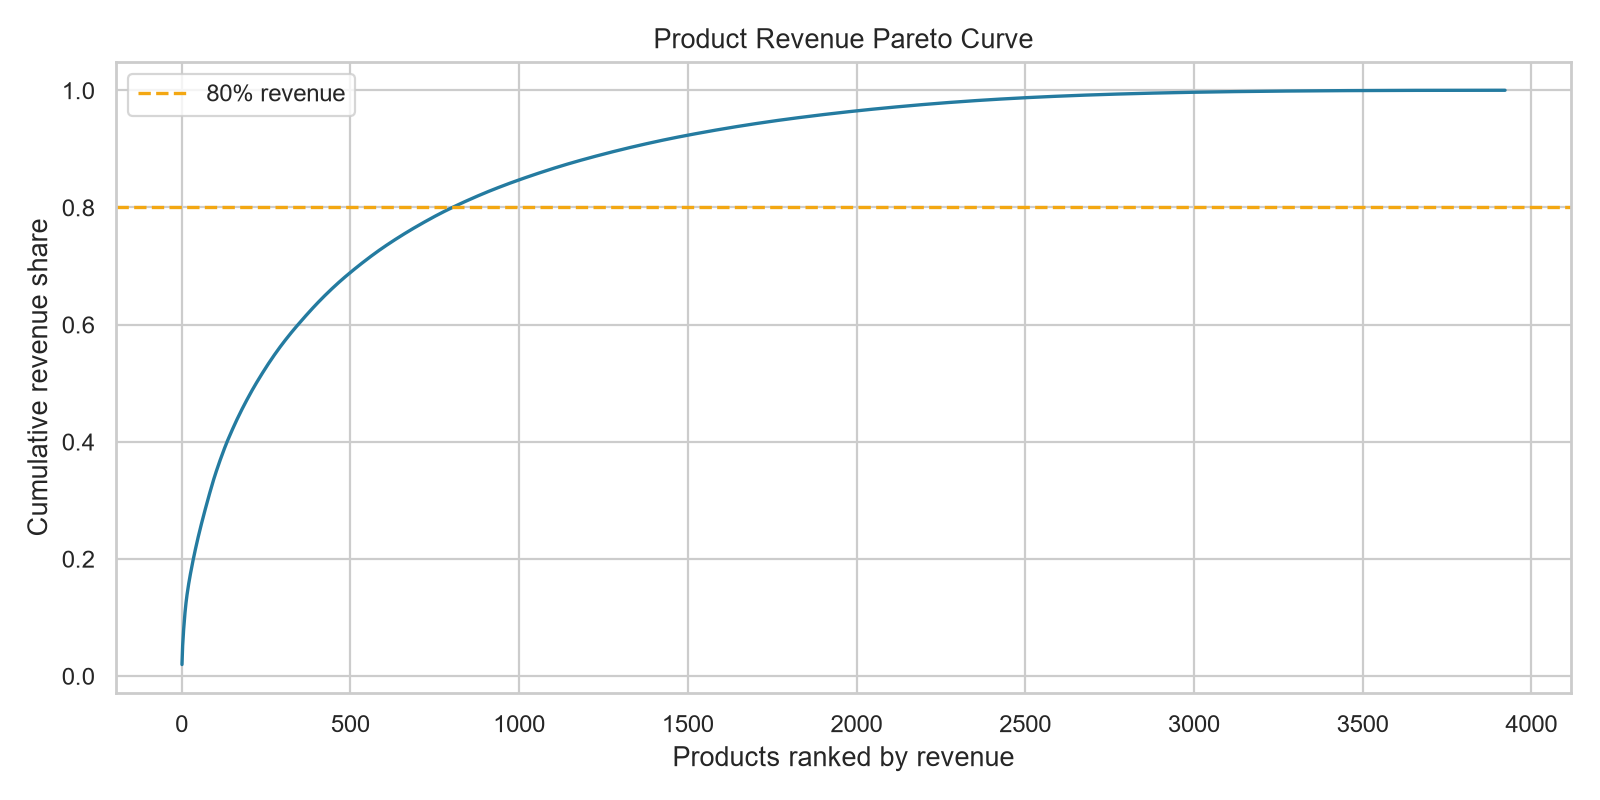

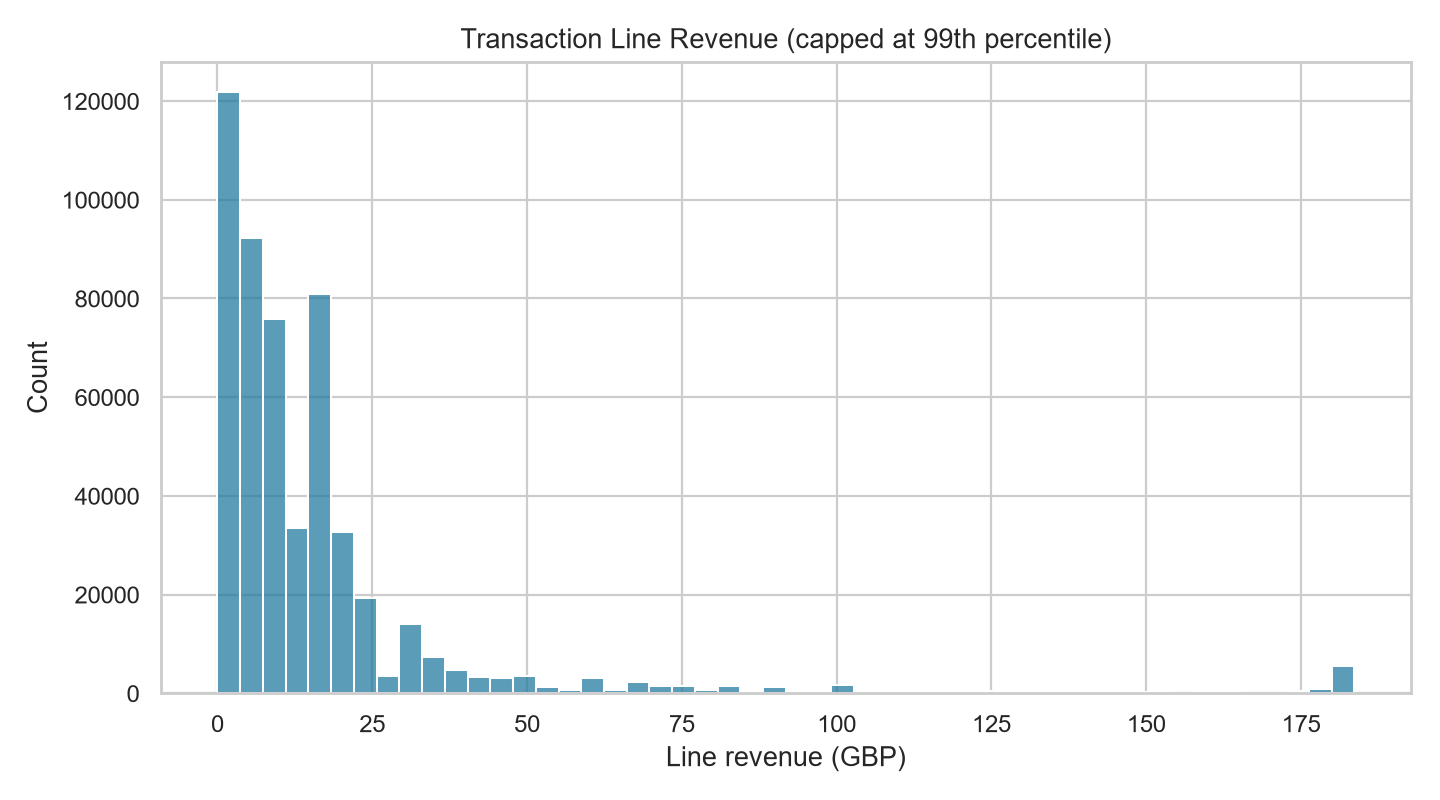

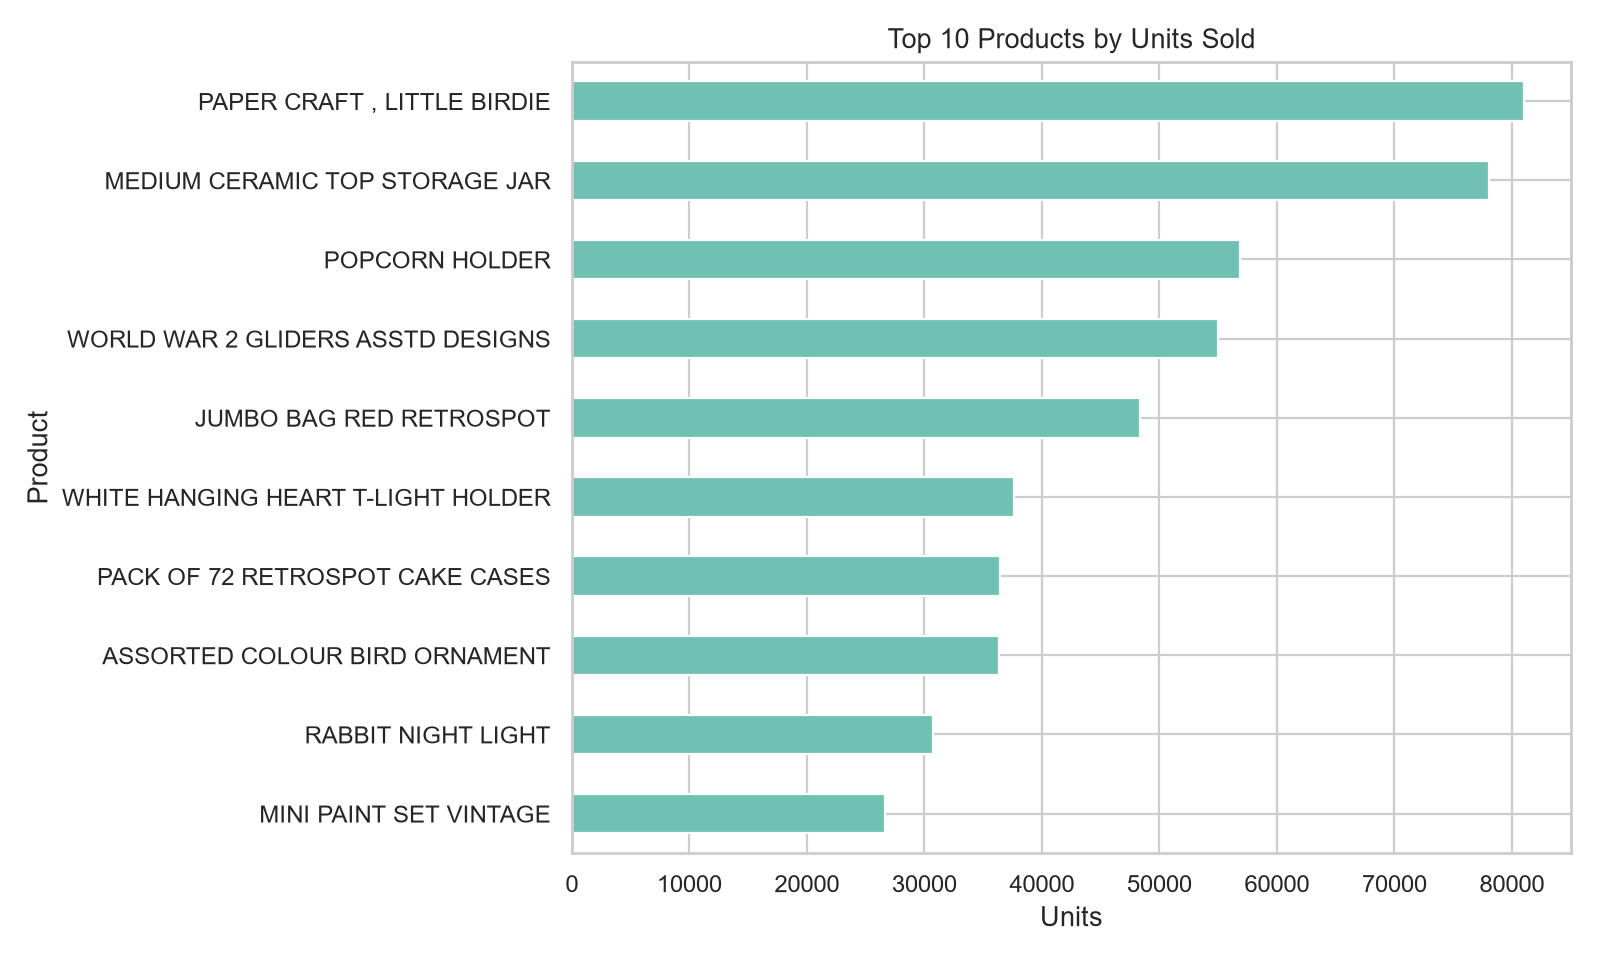

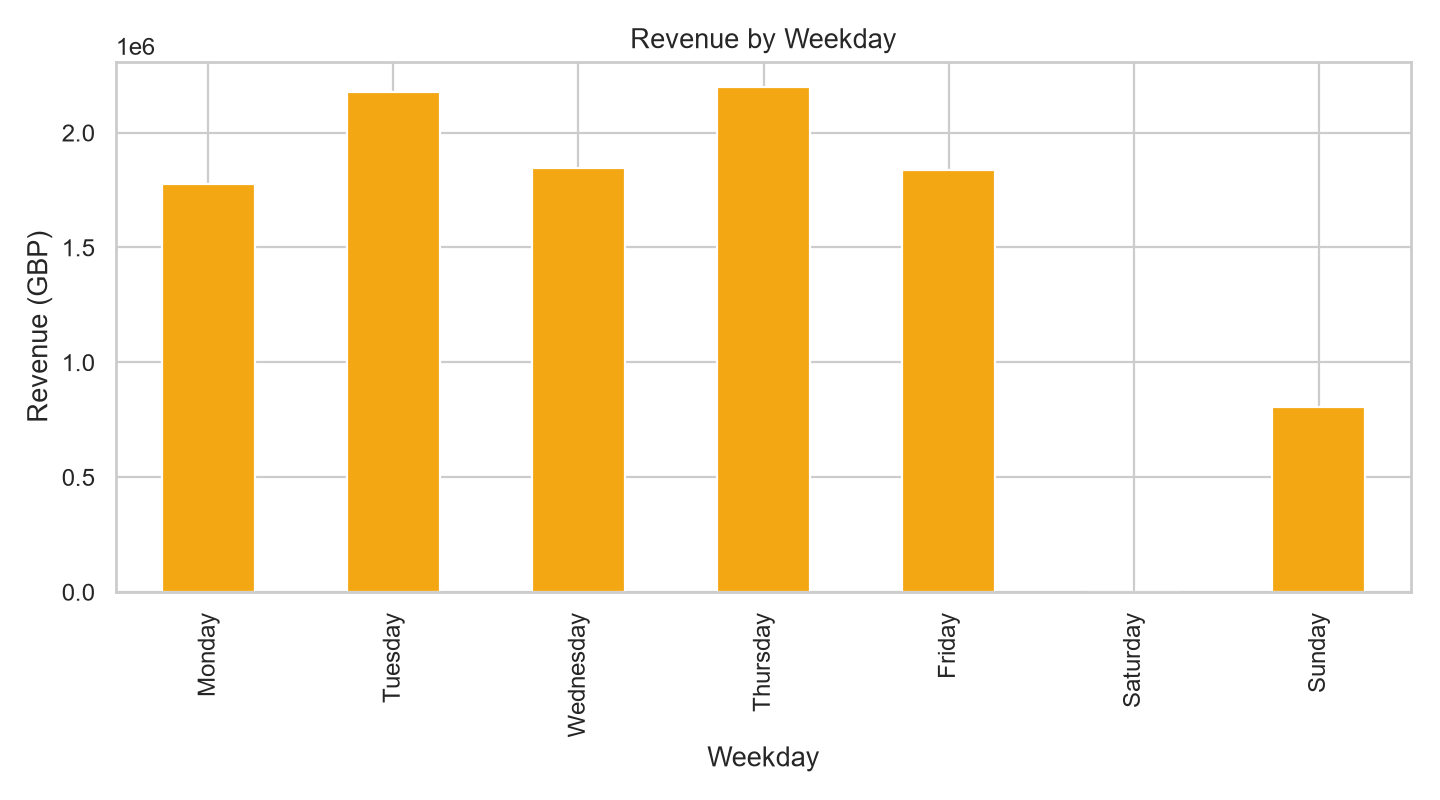

,Computed result
source_file,Online Retail.xlsx
revenue_gbp,10642110.804
valid_sales_lines,524878
unique_sales_invoices,19960
unique_customers,4338
average_order_value_gbp,533.171884
top_country,United Kingdom
top_country_revenue_gbp,9001744.094
top_revenue_product,DOTCOM POSTAGE
top_product_stock_code,DOT


In [11]:
from IPython.display import Image, display
metrics = run_analysis(raw=raw, workbook=workbook)
for path in sorted((ROOT / 'visualizations').glob('*.png')):
    display(Image(filename=str(path), width=900))
display(pd.Series({k:v for k,v in metrics.items() if k not in ['audit','rfm_segment_counts']}, name='Computed result').to_frame())


## 10. Business insights and limitations

Revenue represents deduplicated positive sales, before refunds; it is not net revenue or profit. Anonymous purchases count toward sales but not customer analyses. Cancellation and negative-quantity categories overlap and must not be added together. December 2011 is partial. Cohorts use the first observed purchase rather than proven customer acquisition; blank cells are unobserved future months and zero means no return in an observed month. The final observed month is incomplete for every cohort. Correlations involving TotalPrice partly reflect its definition as Quantity times UnitPrice and do not establish causation. Extreme values are capped only for display in the two histograms, not for calculations.

## 11. Findings and recommended actions

The validated run contains **524,878 valid sales lines**, **19,960 invoices**, and **4,338 known customers**. Positive sales before refunds total **GBP 10,642,110.80**; average invoice value is **GBP 533.17**.

- **Market concentration:** the United Kingdom contributes 84.59% of positive revenue. Examine UK operations before extending recommendations to smaller markets.
- **Product concentration:** 803 of 3,922 stock codes contribute at least 80% of revenue. Prioritize availability after separating service charges and investigating exceptional orders and associated cancellations. The highest revenue code, DOTCOM POSTAGE, is a service charge.
- **Time patterns:** November 2011 leads with GBP 1,503,866.78. December 2011 is partial; its lower total does not establish declining demand.
- **Customer behavior:** 65.58% of known purchasing customers have more than one valid invoice. Use RFM groups to design measurable retention experiments, with results limited by anonymous purchases and the observation window.

Net-sales reconciliation, merchandise classification, and additional periods are the next analytical priorities. These results do not establish causation or estimate profit.
